In [2]:
# Day 24: Student Performance Prediction System
# Step 1: Import Required Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

print("Libraries imported successfully!")
print("Project: Student Performance Prediction System")
print("Day 24: Student Performance Analysis")

Libraries imported successfully!
Project: Student Performance Prediction System
Day 24: Student Performance Analysis


In [3]:
# Step 2: Find Available CSV Datasets

from pathlib import Path

data_folder = Path.cwd()

print("Current folder:", data_folder)
print("\nAvailable CSV files:")

for file in data_folder.glob("*.csv"):
    print(file.name)

Current folder: c:\Users\Bagmita\OneDrive\Desktop\Project

Available CSV files:
day18_model_evaluation_report.csv
day19_model_comparison_report.csv
day20_student_performance_report.csv
day21_student_performance_classification_report.csv
day22_model_evaluation_report.csv
day22_prediction_results.csv
day22_project_summary.csv
day23_student_performance_summary.csv
student_performance_report.csv


In [19]:
from pathlib import Path
import pandas as pd
folder = Path.cwd()
csv_files = list(folder.glob("*.csv"))
for f in csv_files:
    print(f.name)
if csv_files:
    main_file = max(csv_files, key=lambda x: x.stat().st_size)
    print(f"\nLoading: {main_file.name}")
    df = pd.read_csv(main_file)
    print(f"Shape: {df.shape}")
    display(df.head())

day18_model_evaluation_report.csv
day19_model_comparison_report.csv
day20_student_performance_report.csv
day21_student_performance_classification_report.csv
day22_model_evaluation_report.csv
day22_prediction_results.csv
day22_project_summary.csv
day23_student_performance_summary.csv
day24_dataset_quality_report.csv
day24_student_performance_summary.csv
student_performance_report.csv

Loading: student_performance_report.csv
Shape: (10, 9)


,Student_ID,Study_Hours,Attendance,Math_Marks,Science_Marks,Assignments_Completed,Average_Marks,Performance_Level,Study_Recommendation
0,ST101,2,65,42,45,5,43.5,Average,Revise subject fundamentals | Improve class at...
1,ST102,5,85,78,82,9,80.0,Good,Maintain current learning habits
2,ST103,3,70,55,58,6,56.5,Average,Revise subject fundamentals | Improve class at...
3,ST104,8,95,92,94,10,93.0,Excellent,Maintain current learning habits
4,ST105,6,88,81,79,8,80.0,Good,Maintain current learning habits


In [20]:
# Day 24 - Step 4: Dataset Inspection

print("Dataset Information")
print("-" * 40)

print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types and Non-Null Counts:")
df.info()

print("\nMissing Values in Each Column:")
display(df.isnull().sum().to_frame(name="Missing Values"))

print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Information
----------------------------------------
Number of Rows: 10
Number of Columns: 9

Column Names:
['Student_ID', 'Study_Hours', 'Attendance', 'Math_Marks', 'Science_Marks', 'Assignments_Completed', 'Average_Marks', 'Performance_Level', 'Study_Recommendation']

Data Types and Non-Null Counts:
<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Student_ID             10 non-null     str    
 1   Study_Hours            10 non-null     int64  
 2   Attendance             10 non-null     int64  
 3   Math_Marks             10 non-null     int64  
 4   Science_Marks          10 non-null     int64  
 5   Assignments_Completed  10 non-null     int64  
 6   Average_Marks          10 non-null     float64
 7   Performance_Level      10 non-null     str    
 8   Study_Recommendation   10 non-null     str    
dtypes: float64(1), int64(5

,Missing Values
Student_ID,0
Study_Hours,0
Attendance,0
Math_Marks,0
Science_Marks,0
Assignments_Completed,0
Average_Marks,0
Performance_Level,0
Study_Recommendation,0



Duplicate Rows: 0


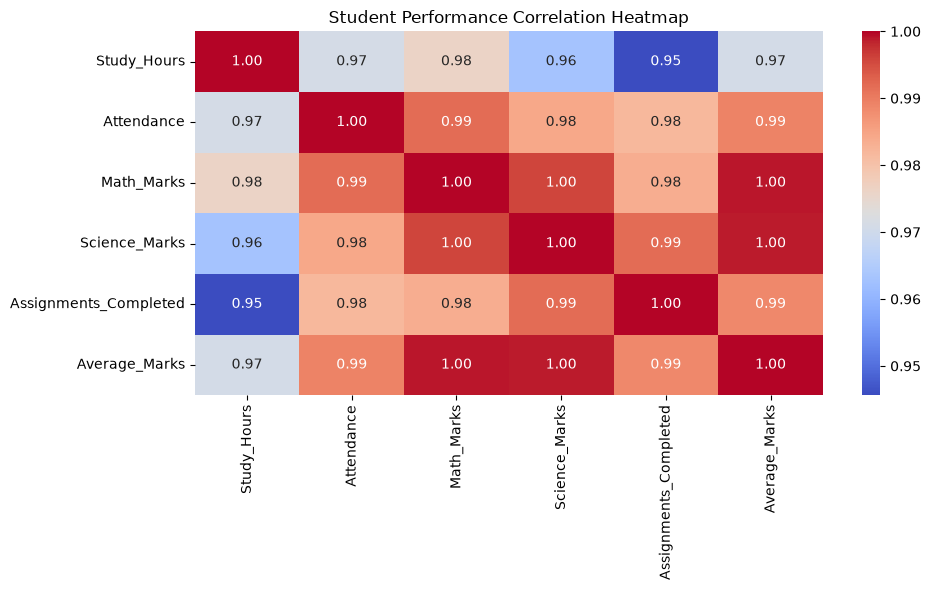

In [21]:
# Day 24 - Step 5: Correlation Analysis

import matplotlib.pyplot as plt
import seaborn as sns

numeric_df = df.select_dtypes(include="number")

if numeric_df.shape[1] >= 2:
    correlation = numeric_df.corr()

    plt.figure(figsize=(10, 6))
    sns.heatmap(
        correlation,
        annot=True,
        cmap="coolwarm",
        fmt=".2f"
    )

    plt.title("Student Performance Correlation Heatmap")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numeric columns to calculate correlation.")

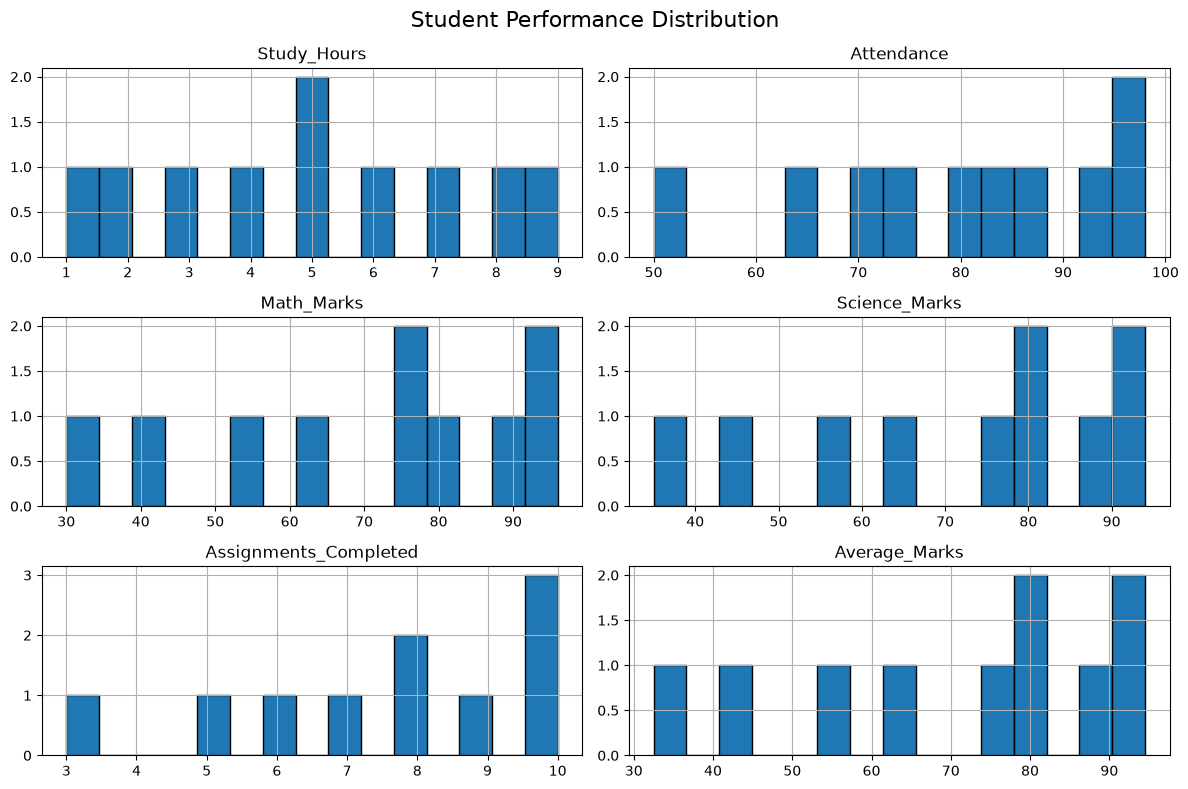

In [22]:
# Day 24 - Step 6: Performance Distribution Analysis

numeric_df = df.select_dtypes(include="number")

if not numeric_df.empty:
    numeric_df.hist(
        figsize=(12, 8),
        bins=15,
        edgecolor="black"
    )

    plt.suptitle("Student Performance Distribution", fontsize=16)
    plt.tight_layout()
    plt.show()
else:
    print("No numeric columns available for distribution analysis.")

In [23]:
# Day 24 - Step 7: Performance Category Analysis

category_candidates = [
    "performance_category",
    "predicted_performance",
    "Performance_Category",
    "Predicted_Performance"
]

category_column = next(
    (col for col in category_candidates if col in df.columns),
    None
)

if category_column is not None:
    print("Category column:", category_column)
    print("\nStudent Count by Category:")

    category_counts = df[category_column].value_counts()
    display(category_counts.to_frame(name="Student Count"))

    category_counts.plot(
        kind="bar",
        figsize=(8, 5),
        edgecolor="black"
    )

    plt.title("Student Performance Categories")
    plt.xlabel("Performance Category")
    plt.ylabel("Number of Students")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("No recognized performance category column found.")
    print("Available columns:", df.columns.tolist())

No recognized performance category column found.
Available columns: ['Student_ID', 'Study_Hours', 'Attendance', 'Math_Marks', 'Science_Marks', 'Assignments_Completed', 'Average_Marks', 'Performance_Level', 'Study_Recommendation']


In [24]:
# Day 24 - Step 8: Model Performance Evaluation

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

actual_candidates = [
    "actual_performance",
    "actual_category",
    "performance_category",
    "Performance_Category"
]

predicted_candidates = [
    "predicted_performance",
    "predicted_category",
    "Predicted_Performance"
]

actual_col = next(
    (col for col in actual_candidates if col in df.columns),
    None
)

predicted_col = next(
    (col for col in predicted_candidates if col in df.columns),
    None
)

if actual_col and predicted_col:
    valid_df = df[[actual_col, predicted_col]].dropna()

    if not valid_df.empty:
        y_true = valid_df[actual_col]
        y_pred = valid_df[predicted_col]

        print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
        print("\nClassification Report:")
        print(classification_report(y_true, y_pred, zero_division=0))

        print("Confusion Matrix:")
        print(confusion_matrix(y_true, y_pred))
    else:
        print("No valid rows available for evaluation.")
else:
    print("Actual or predicted category column not found.")
    print("Available columns:", df.columns.tolist())

Actual or predicted category column not found.
Available columns: ['Student_ID', 'Study_Hours', 'Attendance', 'Math_Marks', 'Science_Marks', 'Assignments_Completed', 'Average_Marks', 'Performance_Level', 'Study_Recommendation']


In [25]:
# Day 24 - Step 9: Create Student Performance Summary

from pathlib import Path

summary_data = {
    "Metric": [
        "Total Students",
        "Total Columns",
        "Missing Values",
        "Duplicate Rows"
    ],
    "Value": [
        len(df),
        len(df.columns),
        int(df.isnull().sum().sum()),
        int(df.duplicated().sum())
    ]
}

summary_df = pd.DataFrame(summary_data)

print("STUDENT PERFORMANCE SUMMARY")
display(summary_df)

output_file = Path.cwd() / "day24_student_performance_summary.csv"
summary_df.to_csv(output_file, index=False)

print("\nSummary saved to:", output_file)

STUDENT PERFORMANCE SUMMARY


,Metric,Value
0,Total Students,10
1,Total Columns,9
2,Missing Values,0
3,Duplicate Rows,0



Summary saved to: c:\Users\Bagmita\OneDrive\Desktop\Project\day24_student_performance_summary.csv


In [26]:
# Day 24 - Step 10: Generate Final Analysis Report

from pathlib import Path
from datetime import datetime

report_lines = [
    "STUDENT PERFORMANCE PREDICTION SYSTEM",
    "DAY 24 - DATA ANALYSIS REPORT",
    "=" * 45,
    f"Report Generated: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}",
    "",
    "DATASET OVERVIEW",
    "-" * 25,
    f"Total Students (Rows): {df.shape[0]}",
    f"Total Columns: {df.shape[1]}",
    f"Total Missing Values: {int(df.isnull().sum().sum())}",
    f"Total Duplicate Rows: {int(df.duplicated().sum())}",
    "",
    "COLUMN DETAILS",
    "-" * 25
]

for column in df.columns:
    report_lines.append(
        f"{column}: {df[column].dtype}, "
        f"Missing={int(df[column].isnull().sum())}"
    )

numeric_df = df.select_dtypes(include="number")

report_lines.extend([
    "",
    "NUMERIC SUMMARY",
    "-" * 25,
    numeric_df.describe().to_string() if not numeric_df.empty
    else "No numeric columns available.",
    "",
    "END OF REPORT"
])

report_text = "\n".join(report_lines)

report_path = Path.cwd() / "day24_student_performance_analysis_report.txt"
report_path.write_text(report_text, encoding="utf-8")

print(report_text)
print("\nReport saved to:", report_path)

STUDENT PERFORMANCE PREDICTION SYSTEM
DAY 24 - DATA ANALYSIS REPORT
Report Generated: 2026-10-20 00:19:10

DATASET OVERVIEW
-------------------------
Total Students (Rows): 10
Total Columns: 9
Total Missing Values: 0
Total Duplicate Rows: 0

COLUMN DETAILS
-------------------------
Student_ID: str, Missing=0
Study_Hours: int64, Missing=0
Attendance: int64, Missing=0
Math_Marks: int64, Missing=0
Science_Marks: int64, Missing=0
Assignments_Completed: int64, Missing=0
Average_Marks: float64, Missing=0
Performance_Level: str, Missing=0
Study_Recommendation: str, Missing=0

NUMERIC SUMMARY
-------------------------
       Study_Hours  Attendance  Math_Marks  Science_Marks  Assignments_Completed  Average_Marks
count    10.000000   10.000000    10.00000      10.000000              10.000000       10.00000
mean      5.000000   79.800000    69.70000      71.600000               7.600000       70.65000
std       2.581989   15.024425    22.04566      20.467861               2.366432       21.2342

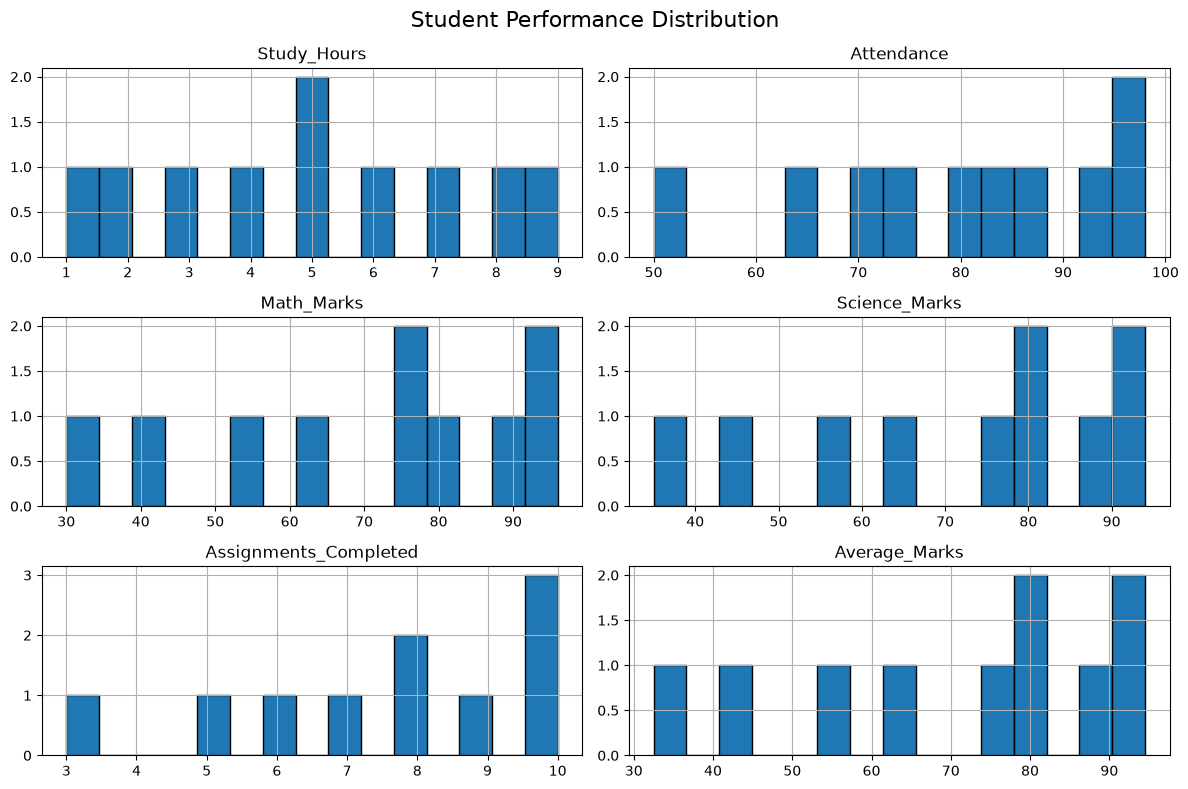

Visualization saved to: c:\Users\Bagmita\OneDrive\Desktop\Project\day24_student_performance_distribution.png


In [27]:
# Day 24 - Step 11: Save Performance Visualization

from pathlib import Path
import matplotlib.pyplot as plt

numeric_df = df.select_dtypes(include="number")
output_path = Path.cwd() / "day24_student_performance_distribution.png"

if not numeric_df.empty:
    axes = numeric_df.hist(
        figsize=(12, 8),
        bins=15,
        edgecolor="black"
    )

    plt.suptitle("Student Performance Distribution", fontsize=16)
    plt.tight_layout()
    plt.savefig(output_path, dpi=150, bbox_inches="tight")
    plt.show()

    print("Visualization saved to:", output_path)
else:
    print("No numeric columns available for visualization.")

In [28]:
# Day 24 - Step 12: Dataset Quality Report

from pathlib import Path
import pandas as pd

quality_report = pd.DataFrame({
    "Column": df.columns,
    "Data_Type": [str(df[col].dtype) for col in df.columns],
    "Missing_Values": [int(df[col].isnull().sum()) for col in df.columns],
    "Unique_Values": [int(df[col].nunique()) for col in df.columns]
})

print("DATASET QUALITY REPORT")
display(quality_report)

output_path = Path.cwd() / "day24_dataset_quality_report.csv"
quality_report.to_csv(output_path, index=False)

print("Quality report saved to:", output_path)

DATASET QUALITY REPORT


,Column,Data_Type,Missing_Values,Unique_Values
0,Student_ID,str,0,10
1,Study_Hours,int64,0,9
2,Attendance,int64,0,10
3,Math_Marks,int64,0,10
4,Science_Marks,int64,0,10
5,Assignments_Completed,int64,0,7
6,Average_Marks,float64,0,9
7,Performance_Level,str,0,4
8,Study_Recommendation,str,0,3


Quality report saved to: c:\Users\Bagmita\OneDrive\Desktop\Project\day24_dataset_quality_report.csv


In [29]:
# Day 24 - Step 13: Verify Project Outputs

from pathlib import Path

expected_files = [
    "day24_student_performance_summary.csv",
    "day24_student_performance_analysis_report.txt",
    "day24_student_performance_distribution.png",
    "day24_dataset_quality_report.csv"
]

print("DAY 24 PROJECT VERIFICATION")
print("=" * 40)

for filename in expected_files:
    file_path = Path.cwd() / filename

    if file_path.exists():
        print(f"[OK] {filename} ({file_path.stat().st_size:,} bytes)")
    else:
        print(f"[MISSING] {filename}")

print("\nDataset shape:", df.shape)
print("Project: Student Performance Prediction System")
print("Day: 24")

DAY 24 PROJECT VERIFICATION
[OK] day24_student_performance_summary.csv (86 bytes)
[OK] day24_student_performance_analysis_report.txt (1,578 bytes)
[OK] day24_student_performance_distribution.png (83,332 bytes)
[OK] day24_dataset_quality_report.csv (280 bytes)

Dataset shape: (10, 9)
Project: Student Performance Prediction System
Day: 24


In [30]:
# Day 24 - Step 14: Create README File

from pathlib import Path

readme_content = """# Student Performance Prediction System

## Day 24: Student Performance Analysis

### Project Overview
This project analyzes student performance data using Python
and generates summary reports and visualizations.

### Technologies Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn

### Features
- Dataset inspection
- Missing-value and duplicate analysis
- Correlation heatmap
- Numeric distribution visualization
- Dataset quality report
- Summary report generation

### Output Files
- day24_student_performance_summary.csv
- day24_student_performance_analysis_report.txt
- day24_student_performance_distribution.png
- day24_dataset_quality_report.csv

### How to Run
1. Open the notebook in Jupyter.
2. Ensure the required dataset is available.
3. Run the notebook cells in order.

Note: Model accuracy evaluation is performed only if suitable
actual and predicted category columns are available.
"""

readme_path = Path.cwd() / "day24_README.md"
readme_path.write_text(readme_content, encoding="utf-8")

print("README created successfully!")
print("Saved at:", readme_path)

README created successfully!
Saved at: c:\Users\Bagmita\OneDrive\Desktop\Project\day24_README.md


In [31]:
# Day 24 - Step 15: Verify Required Libraries

import pandas as pd
import numpy as np
import matplotlib
import seaborn as sns
import sklearn

print("Required libraries verified successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Matplotlib version:", matplotlib.__version__)
print("Seaborn version:", sns.__version__)
print("Scikit-learn version:", sklearn.__version__)

Required libraries verified successfully!
Pandas version: 3.0.6
NumPy version: 2.5.3
Matplotlib version: 3.11.2
Seaborn version: 0.13.2
Scikit-learn version: 1.9.1


In [32]:
# Day 24 - Step 16: Final Project Status Summary

from pathlib import Path

print("=" * 55)
print("STUDENT PERFORMANCE PREDICTION SYSTEM")
print("DAY 24 - PROJECT STATUS SUMMARY")
print("=" * 55)

print("\nDataset Information")
print("-" * 30)
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])
print("Missing values:", int(df.isnull().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

print("\nGenerated Output Files")
print("-" * 30)

output_files = [
    "day24_student_performance_summary.csv",
    "day24_student_performance_analysis_report.txt",
    "day24_student_performance_distribution.png",
    "day24_dataset_quality_report.csv",
    "day24_README.md"
]

for filename in output_files:
    file_path = Path.cwd() / filename
    status = "Created" if file_path.exists() else "Not found"
    print(f"{filename}: {status}")

print("\nProject analysis workflow completed.")

STUDENT PERFORMANCE PREDICTION SYSTEM
DAY 24 - PROJECT STATUS SUMMARY

Dataset Information
------------------------------
Total rows: 10
Total columns: 9
Missing values: 0
Duplicate rows: 0

Generated Output Files
------------------------------
day24_student_performance_summary.csv: Created
day24_student_performance_analysis_report.txt: Created
day24_student_performance_distribution.png: Created
day24_dataset_quality_report.csv: Created
day24_README.md: Created

Project analysis workflow completed.
